In [1]:
# import modules
import numpy as np
import tensorflow as tf
from tensorflow import keras

import pandas as pd
import seaborn as sns
from pylab import rcParams
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupShuffleSplit
from scipy import stats
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split
from tensorflow.keras import optimizers
from datetime import datetime
from kerastuner.tuners import RandomSearch
import tensorflow_addons as tfa
from keras.utils import to_categorical 
from keras.regularizers import l2
import time




bloco = 0
r_seed = 42

WORKDIR = 'C:/Users/thewr/git/LSTM_giroscopio_acelerometro.git/'
np.random.seed(r_seed)
tf.random.set_seed(r_seed)
data_hora= datetime.now().strftime('%Y-%m-%d_%H-%M-%S')
LOG_DIR = WORKDIR + "/Code/DataPrep/"+data_hora

C:\Users\cristiano.nascimento\AppData\Local\Temp\ipykernel_11732\2696971385.py:16: DeprecationWarning: `import kerastuner` is deprecated, please use `import keras_tuner`.
  from kerastuner.tuners import RandomSearch
c:\Users\cristiano.nascimento\git\LSTM_giroscopio_acelerometro\.venv\lib\site-packages\tensorflow_addons\utils\tfa_eol_msg.py:23: UserWarning: 

TensorFlow Addons (TFA) has ended development and introduction of new features.
TFA has entered a minimal maintenance and release mode until a planned end of life in May 2024.
Please modify downstream libraries to take dependencies from other repositories in our TensorFlow community (e.g. Keras, Keras-CV, and Keras-NLP). 

For more information see: https://github.com/tensorflow/addons/issues/2807 

  warnings.warn(


In [2]:
date = datetime.now()
date = date.strftime("%d/%m/%Y_%H:%M")
arq = datetime.now()
arq = arq.strftime("%d_%m_%Y_%H_%M")

In [3]:
pd.set_option("display.precision", 9)

In [4]:
## get dataset

# select only sensor data from smart watches
data = pd.read_csv('activity_recognition_data_watch_concat_by_comparacao_grupos.csv',dtype={"value": "float64"})

In [5]:
data.head(10)

,pessoa_x,atividade,tempo_acelerômetro,acelerômetro_x,acelerômetro_Y,acelerômetro_Z,tempo_gyro,giroscópio_x,giroscópio_Y,giroscópio_Z
0,1600,0,90426708196641,7.0916250,-0.59166710,8.1955020,90426757696641,0.314944100,-1.02227650,-0.309961600
1,1600,0,90426757696641,4.9727570,-0.15831658,6.6967316,90426807196641,0.387382100,-0.61854124,-0.048971802
2,1600,0,90426807196641,3.2537200,-0.19183542,6.1077580,90426856696641,0.070998540,-0.20947972,-0.195978300
3,1600,0,90426856696641,2.8012160,-0.15592238,5.9976250,90426906196641,0.037975345,0.25497556,-0.156563500
4,1600,0,90426906196641,3.7708676,-1.05135380,7.7310270,90426955696641,0.073129070,0.71943086,-0.001034904
5,1600,0,90426955696641,4.6615110,0.16968904,9.6846950,90427005196641,-0.101574294,1.08268610,-0.134192960
6,1600,0,90427005196641,6.1459160,0.83288294,11.0039010,90427054696641,-0.677882400,1.17642930,-0.211957260
7,1600,0,90427054696641,7.2592196,-0.79278004,11.4851350,90427104196641,-0.163359630,1.01983550,0.303630700
8,1600,0,90427104196641,7.3549876,-2.53575900,11.4540110,90427153696641,0.412948430,0.99000800,0.994987300
9,1600,0,90427153696641,7.3190746,-2.70095870,11.4611930,90427203196641,0.286181960,0.78654253,1.180343400


In [6]:
data.isnull().sum()

pessoa_x              0
atividade             0
tempo_acelerômetro    0
acelerômetro_x        0
acelerômetro_Y        0
acelerômetro_Z        0
tempo_gyro            0
giroscópio_x          0
giroscópio_Y          0
giroscópio_Z          0
dtype: int64

In [7]:
#remove the null class
data=data.dropna()

In [8]:
data=data[data["pessoa_x"]!=1629]

# **Data Exploration**

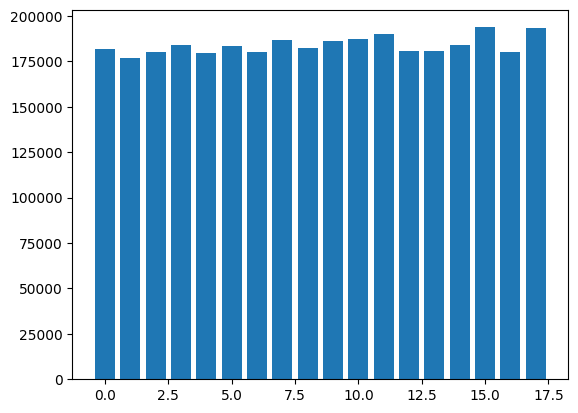

In [9]:
## the distribution of output classes
plt.bar(data["atividade"].value_counts().index, data["atividade"].value_counts().values)
plt.show()

array([<Axes: >, <Axes: >, <Axes: >], dtype=object)

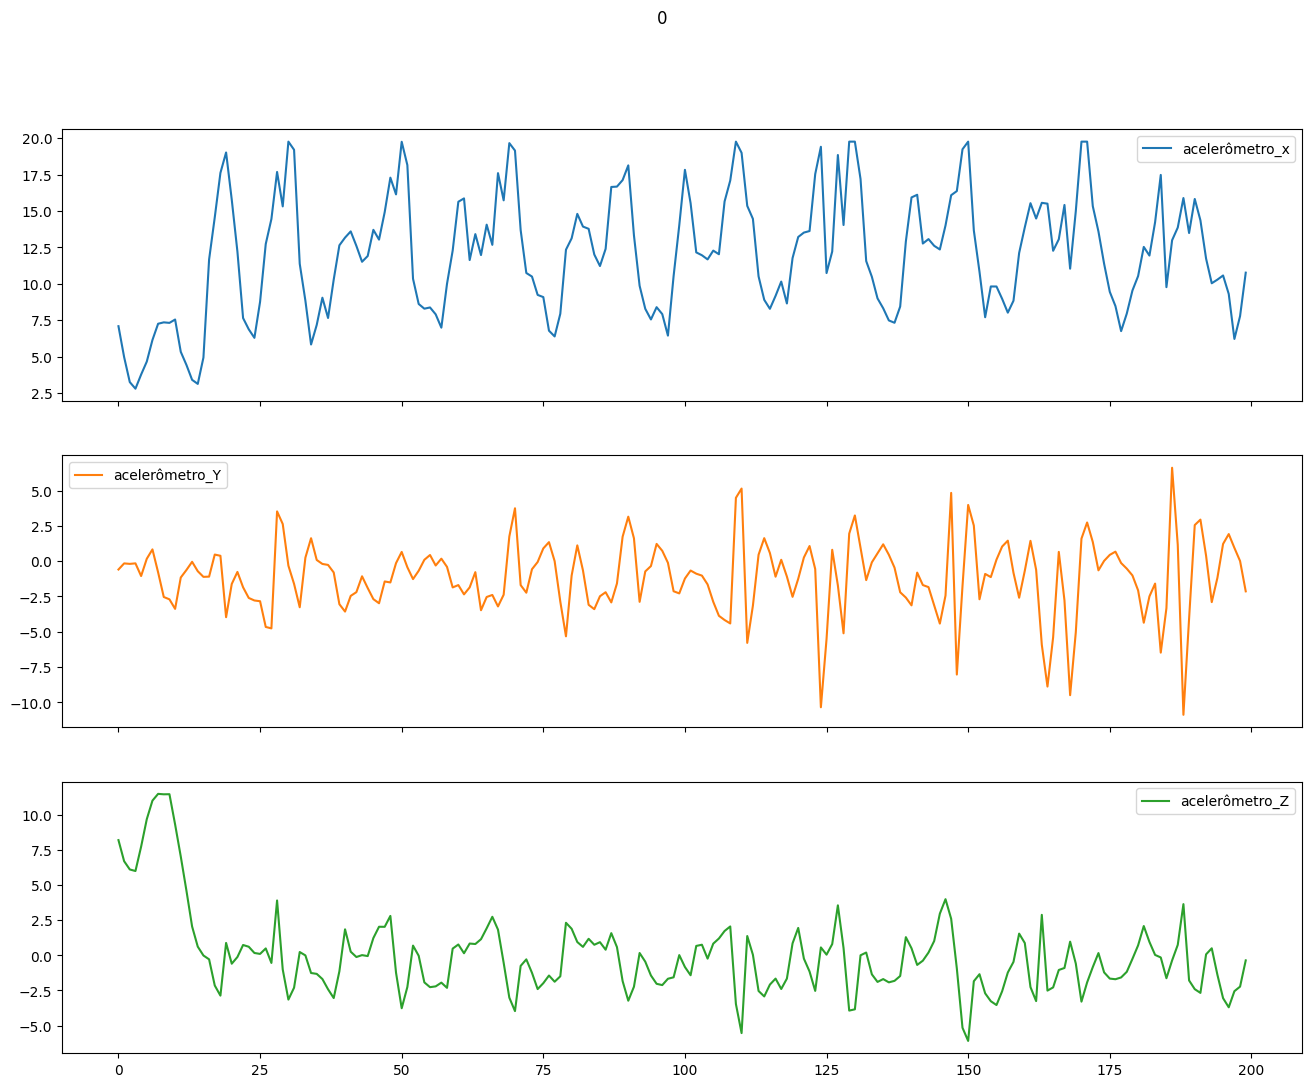

In [10]:
## x,y,z vaues for activity 'sit' 
data[(data['atividade'] == 0 )&(data['pessoa_x']==1600)][['acelerômetro_x','acelerômetro_Y','acelerômetro_Z']][:200].plot(title='0',subplots=True, figsize=(16, 12))

array([<Axes: >, <Axes: >, <Axes: >], dtype=object)

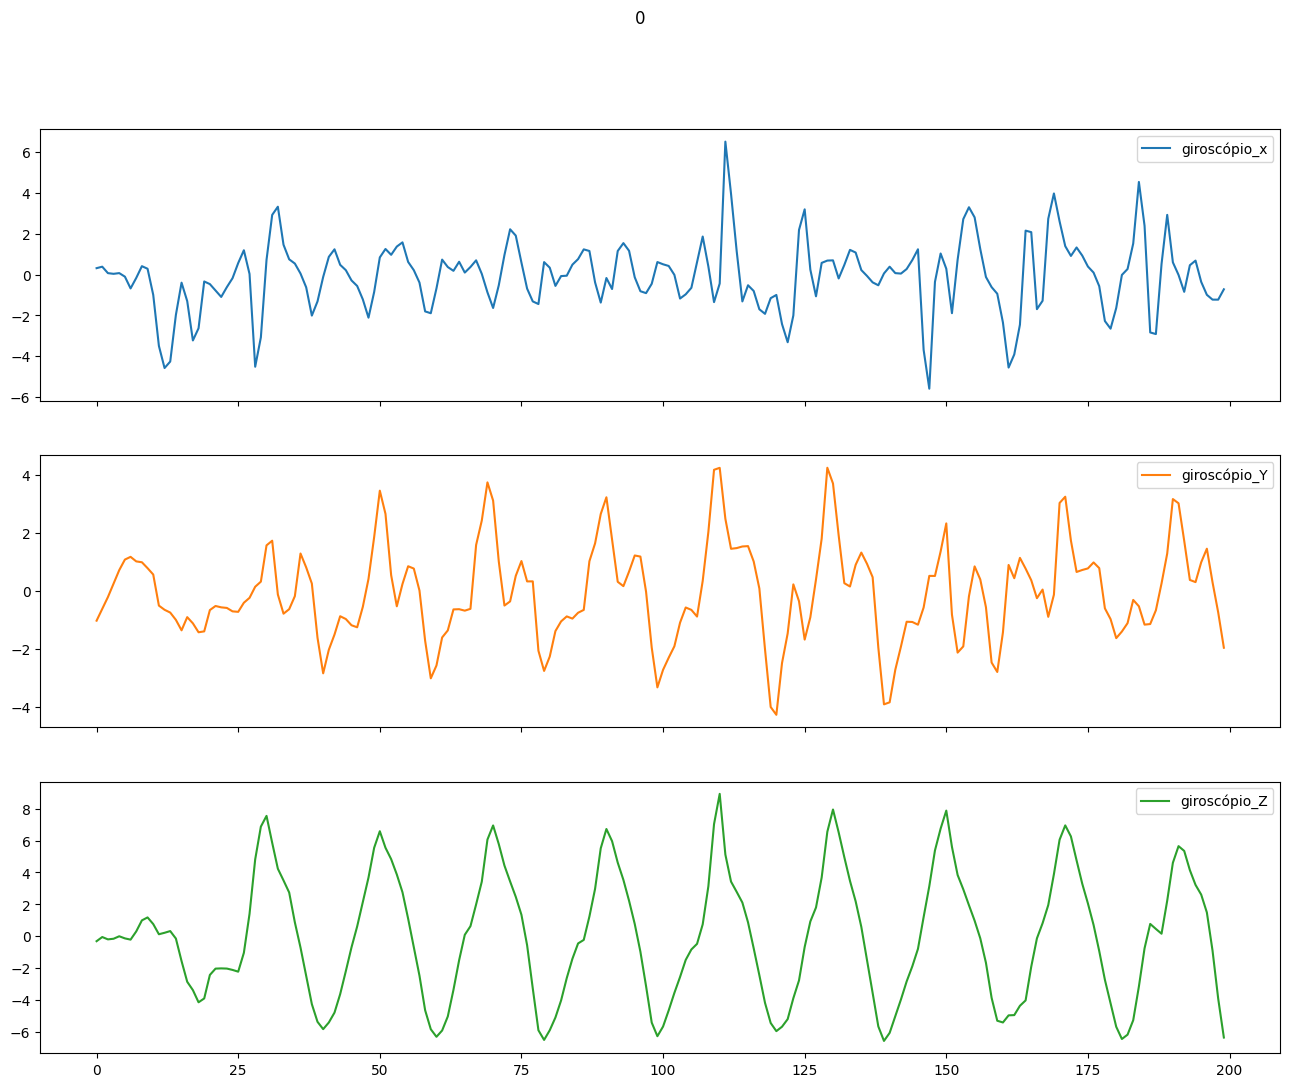

In [11]:
## x,y,z vaues for activity 'stand' 
data[(data['atividade'] == 0 )&(data['pessoa_x']==1600)][['giroscópio_x','giroscópio_Y','giroscópio_Z']][:200].plot(title='0',subplots=True, figsize=(16, 12))

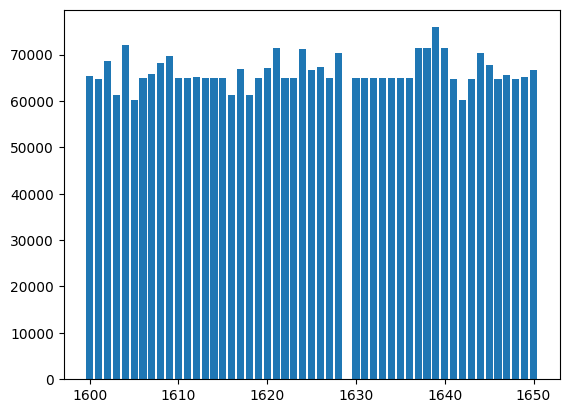

In [12]:
## number of events per user

plt.bar(data["pessoa_x"].value_counts().index, data["pessoa_x"].value_counts().values)
plt.show()

In [13]:
#selecting only activities 0 to 3
data = data[data["atividade"].isin([0,1,2,3])]

In [14]:
data.shape

(723387, 10)

In [15]:
data.head()

,pessoa_x,atividade,tempo_acelerômetro,acelerômetro_x,acelerômetro_Y,acelerômetro_Z,tempo_gyro,giroscópio_x,giroscópio_Y,giroscópio_Z
0,1600,0,90426708196641,7.0916250,-0.59166710,8.1955020,90426757696641,0.314944100,-1.02227650,-0.309961600
1,1600,0,90426757696641,4.9727570,-0.15831658,6.6967316,90426807196641,0.387382100,-0.61854124,-0.048971802
2,1600,0,90426807196641,3.2537200,-0.19183542,6.1077580,90426856696641,0.070998540,-0.20947972,-0.195978300
3,1600,0,90426856696641,2.8012160,-0.15592238,5.9976250,90426906196641,0.037975345,0.25497556,-0.156563500
4,1600,0,90426906196641,3.7708676,-1.05135380,7.7310270,90426955696641,0.073129070,0.71943086,-0.001034904


In [16]:
data = data.reset_index()

In [17]:
data.head()

,index,pessoa_x,atividade,tempo_acelerômetro,acelerômetro_x,acelerômetro_Y,acelerômetro_Z,tempo_gyro,giroscópio_x,giroscópio_Y,giroscópio_Z
0,0,1600,0,90426708196641,7.0916250,-0.59166710,8.1955020,90426757696641,0.314944100,-1.02227650,-0.309961600
1,1,1600,0,90426757696641,4.9727570,-0.15831658,6.6967316,90426807196641,0.387382100,-0.61854124,-0.048971802
2,2,1600,0,90426807196641,3.2537200,-0.19183542,6.1077580,90426856696641,0.070998540,-0.20947972,-0.195978300
3,3,1600,0,90426856696641,2.8012160,-0.15592238,5.9976250,90426906196641,0.037975345,0.25497556,-0.156563500
4,4,1600,0,90426906196641,3.7708676,-1.05135380,7.7310270,90426955696641,0.073129070,0.71943086,-0.001034904


In [18]:
data.shape

(723387, 11)

# **Models**

In [19]:
def split_indices_for_kfold(validation_sets):
    split_indices = np.empty((10, 2))
    position = 0
    for set in validation_sets:
        start_validation_index = data[(data['pessoa_x'].isin(set))].head(1).index[0]
        end_validation_index = data[(data['pessoa_x'].isin(set))].tail(1).index[0]
        split_indices[position]= [start_validation_index,end_validation_index]
        position = position + 1
    return split_indices       


In [20]:

validation_set8=np.arange(1636,1641)
validation_set9=np.arange(1641,1646)
validation_set10=np.arange(1646,1651)
validation_set1=np.arange(1600,1605)
validation_set2=np.arange(1605,1610)
validation_set3=np.arange(1610,1615)
validation_set4=np.arange(1615,1620)
validation_set5=np.arange(1620,1625)
validation_set6=np.arange(1625,1631)
validation_set7=np.arange(1631,1636)
combined_validation_sets = [validation_set8, validation_set9, validation_set10, validation_set1,
validation_set2,validation_set3,validation_set4,validation_set5,validation_set6,validation_set7]
split_indices = split_indices_for_kfold(combined_validation_sets)

In [21]:
print(split_indices[0])

[501516. 578405.]


In [22]:
for elem1,elem2 in split_indices:    
        print(f"{elem1}-{elem2} -- total percentual={(elem2-elem1)/data.shape[0]}")    

501516.0-578405.0 -- total percentual=0.10629027062969061
578406.0-648955.0 -- total percentual=0.0975259439276625
648956.0-723386.0 -- total percentual=0.10289098366434564
0.0-72050.0 -- total percentual=0.09960090518629723
72051.0-140500.0 -- total percentual=0.0946229335058551
140501.0-212560.0 -- total percentual=0.09961334665953356
212561.0-281004.0 -- total percentual=0.09461463919036421
281005.0-357367.0 -- total percentual=0.10556175325240846
357368.0-429450.0 -- total percentual=0.09964514153558192
429451.0-501515.0 -- total percentual=0.09962025858910929


In [23]:
def delete_segments_not_fully_filled(df_data_windowed,df_label_windowed):
    indexes = np.where(df_label_windowed == -1)[0]
    unique_arr = np.unique(indexes, return_index=True)[0]
    new_df_label_windowed = np.delete(df_label_windowed,unique_arr,axis=0)
    new_df_data_windowed = np.delete(df_data_windowed,unique_arr,axis=0)
    return (new_df_data_windowed,new_df_label_windowed)

In [24]:
def apply_segmentation_with_sliding_window(df_data):
    #creating sliding window for train data
    import numpy as np

    window_size = 200
    step_size = 20

    n_windows = int((df_data.shape[0] - window_size) // step_size + 1)

    segments = np.zeros((n_windows, window_size, df_data.shape[1]-1),dtype=np.float32)
    targets = np.full((n_windows, window_size, 1),-1)
    for i in range(n_windows):
        start_idx = i * step_size
        end_idx = start_idx + window_size
        label_consistency = df_data[['atividade']][start_idx:end_idx].nunique()==1
        if label_consistency[0] == True:
            segments[i] = df_data[['acelerômetro_x', 'acelerômetro_Y', 'acelerômetro_Z', 'giroscópio_x', 'giroscópio_Y', 'giroscópio_Z']][start_idx:end_idx]
            targets[i] = df_data[['atividade']][start_idx:end_idx]
    return (segments,targets)

In [25]:
def shuffle_data(variable_data,label_data):
    perm_indices = np.random.permutation(variable_data.shape[0])
    # Shuffle both arrays using the same permutation indices
    shuffled_variable_data = variable_data[perm_indices]
    shuffled_label_data = label_data[perm_indices]
    return (shuffled_variable_data,shuffled_label_data)

In [26]:
def cria_LSTM():
  model = tf.keras.Sequential()  
  model.add(tf.keras.layers.LSTM(units=128, kernel_regularizer=l2(0.0005377164071193433),
             recurrent_regularizer=l2(0.0005377164071193433), input_shape=(200,6), return_sequences=False))  
  model.add(tf.keras.layers.Dense(units = 256, activation='relu'))  
  model.add(tf.keras.layers.Dense(units=4, activation='softmax'))
  model.compile(loss='categorical_crossentropy', optimizer=tf.keras.optimizers.Adam(learning_rate=0.001715074355925934), metrics=['accuracy'])
  return model


In [27]:
def create_validation_and_train_data(start_index,end_index):
    global bloco
    current_time = time.time() * 1000
    print(f"Current time in milliseconds: {current_time:.2f}")
    print("indices que serão processados")
    print("Proximo bloco:")
    print(bloco)
    print(start_index)
    print(end_index)
    
    X_validation_data = data.iloc[int(start_index):int(end_index + 1)]
    X_train_data = data.drop(index=data.index[int(start_index):int(end_index + 1)])
    #print(X_validation_data)
    #print(X_train_data)

    X_validation_data = X_validation_data.reset_index(drop=True)
    X_validation_data = X_validation_data.drop('index',axis=1)
    X_validation_data.info()
    X_validation_data['atividade'].value_counts()
    X_validation_data = X_validation_data[['acelerômetro_x', 'acelerômetro_Y', 'acelerômetro_Z', 'giroscópio_x', 'giroscópio_Y', 'giroscópio_Z','atividade']]
    print(X_validation_data.shape)

    X_train_data = X_train_data.reset_index(drop=True)
    X_train_data = X_train_data.drop('index',axis=1)
    X_train_data['atividade'].value_counts()
    X_train_data = X_train_data[['acelerômetro_x', 'acelerômetro_Y', 'acelerômetro_Z', 'giroscópio_x', 'giroscópio_Y', 'giroscópio_Z','atividade']]
    print(X_train_data.shape)

    segments_val,targets_val = apply_segmentation_with_sliding_window(X_validation_data)
    print(targets_val.shape)
    print(segments_val.shape)

    segments_val,targets_val = delete_segments_not_fully_filled(segments_val,targets_val)
    print(targets_val.shape)
    print(segments_val.shape)
    print("fez a segmentação da validação no horário")
    current_time = time.time() * 1000
    print(f"Current time in milliseconds: {current_time:.2f}")
    targets_val = targets_val.reshape(targets_val.shape[0],200)
    print(targets_val.shape)
    print(targets_val)
    labels_val = targets_val[:,0]
    print(labels_val)
    print(labels_val.shape)
    labels_val_categorical = to_categorical(labels_val,num_classes=4)
    print(labels_val_categorical)
    print(labels_val_categorical.shape)
    segments_train,targets_train = apply_segmentation_with_sliding_window(X_train_data)
    print(segments_train.shape)
    print(targets_train.shape)

    segments_train, targets_train = delete_segments_not_fully_filled(segments_train,targets_train)
    print(segments_train.shape)
    print(targets_train.shape)
    print("fez a segmentação do treino no horário")
    current_time = time.time() * 1000
    print(f"Current time in milliseconds: {current_time:.2f}")

    targets_train = targets_train.reshape(targets_train.shape[0],200)
    print(targets_train.shape)
    labels_train = targets_train[:,0]
    labels_train_categorical = to_categorical(labels_train,num_classes=4)
    print(labels_train_categorical)

    X_train = segments_train
    y_train = labels_train_categorical
    X_validation = segments_val
    y_validation = labels_val_categorical

    print(X_train.shape)
    print(y_train.shape)
    print(X_validation.shape)
    print(y_validation.shape)

    X_train,y_train = shuffle_data(X_train,y_train)
    X_validation,y_validation = shuffle_data(X_validation,y_validation)

    print(X_train.shape)
    print(y_train.shape)
    print(X_validation.shape)
    print(y_validation.shape)
    bloco = bloco+1
    print(f" %%%%%%%%%%%%%%%%%%%%%%%%%%%% retornou os dados para treinamento de {start_index} e {end_index} %%%%%%%%%%%%%%%%%%%%")
    return (X_train,y_train,X_validation,y_validation)

In [28]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    min_delta = 0,
    verbose=1,
    restore_best_weights=True)

my_callbacks = [early_stopping]  

In [29]:
#for start_index,end_index in split_indices:    
        #print(f"************ Usando indices {start_index} e {end_index} como teste ******************* ")     

************ Usando indices 501516.0 e 578405.0 como teste ******************* 
Current time in milliseconds: 1709687972785.66
indices que serão processados
Proximo bloco:
0
501516.0
578405.0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 76890 entries, 0 to 76889
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   pessoa_x            76890 non-null  int64  
 1   atividade           76890 non-null  int64  
 2   tempo_acelerômetro  76890 non-null  int64  
 3   acelerômetro_x      76890 non-null  float64
 4   acelerômetro_Y      76890 non-null  float64
 5   acelerômetro_Z      76890 non-null  float64
 6   tempo_gyro          76890 non-null  int64  
 7   giroscópio_x        76890 non-null  float64
 8   giroscópio_Y        76890 non-null  float64
 9   giroscópio_Z        76890 non-null  float64
dtypes: float64(6), int64(4)
memory usage: 5.9 MB
(76890, 7)
(646497, 7)
(3835, 200, 1)
(3835, 200, 6)
(3666, 2

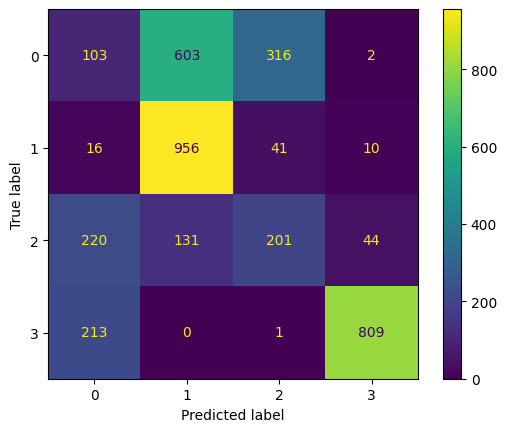

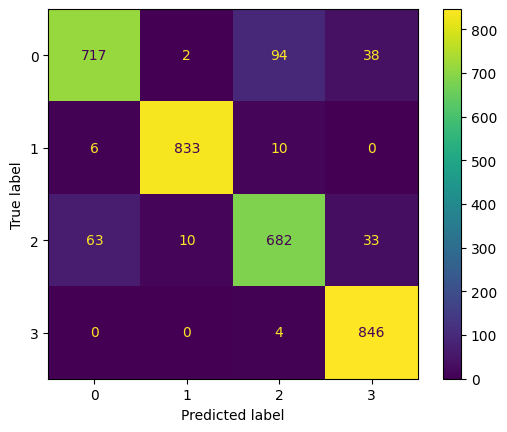

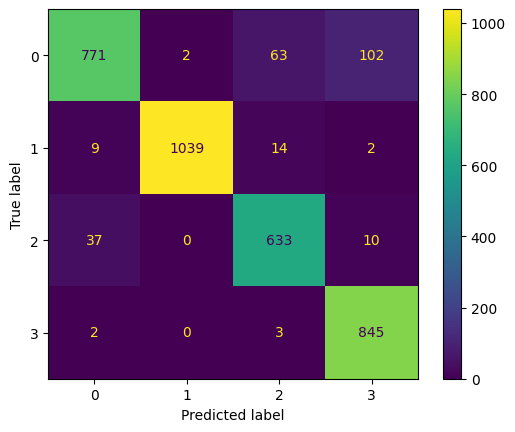

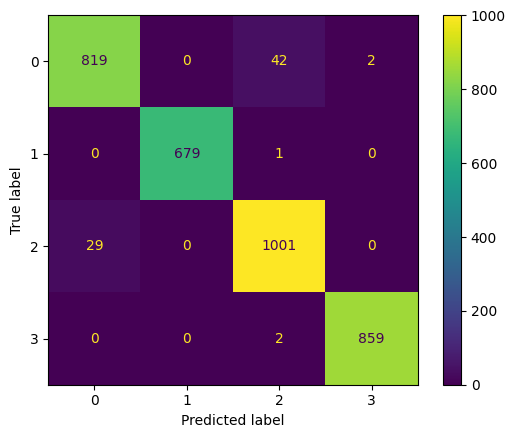

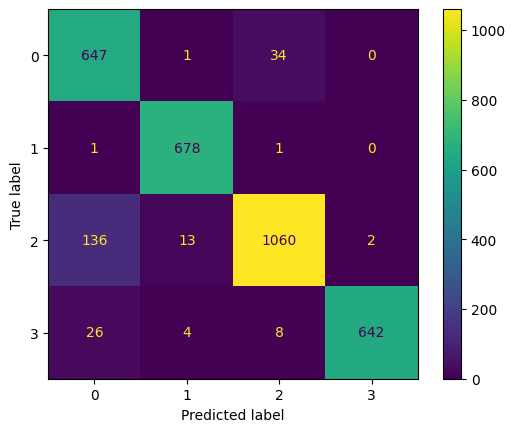

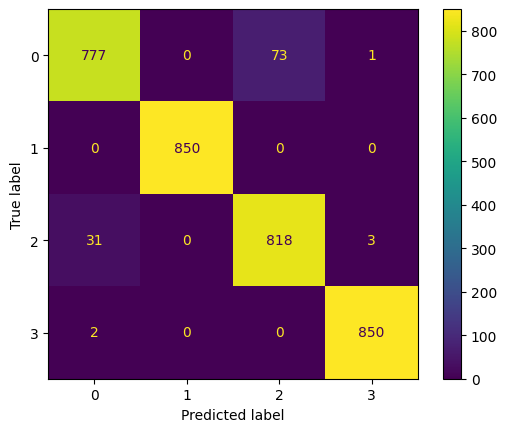

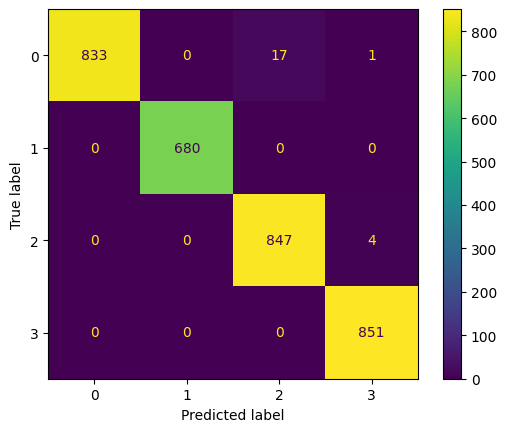

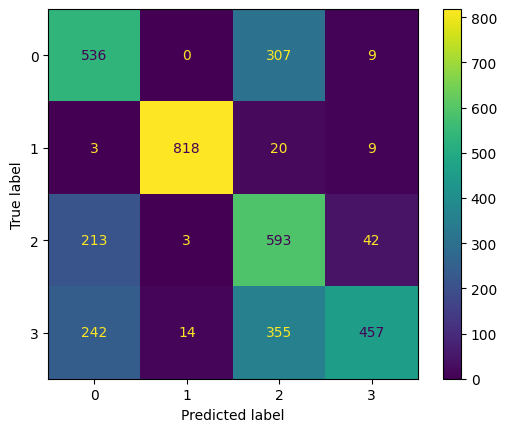

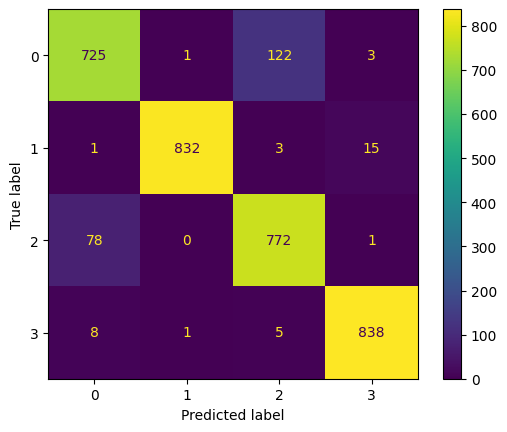

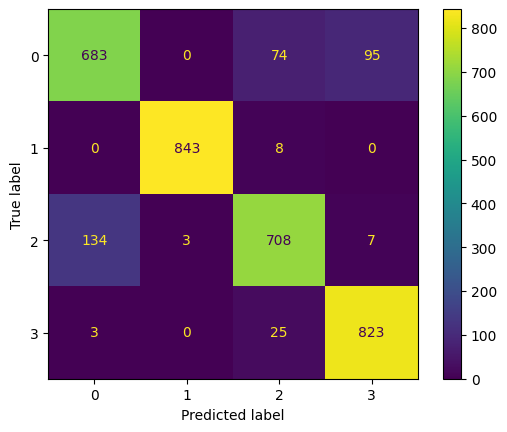

In [30]:
accuracies = []
for start_index,end_index in split_indices:
        print(f"************ Usando indices {start_index} e {end_index} como teste ******************* ")    
        X_train,y_train,X_validation,y_validation = create_validation_and_train_data(start_index,end_index)
        print (X_train)
        model  = cria_LSTM()
        model.fit(X_train, y_train, epochs=50, batch_size=32, validation_data=(X_validation, y_validation),use_multiprocessing=True,callbacks=[my_callbacks])  # Adjust epochs and batch size
        _, accuracy = model.evaluate(X_validation, y_validation)
        print(f"===============>Appending accuracy of {accuracy} ") 
        accuracies.append(accuracy)

        loss, accuracy = model.evaluate(X_validation, y_validation)
        predictions = model.predict(X_validation)
        print(y_validation)
        print(y_validation.shape)
        y_validation_inverse = np.argmax(y_validation, axis=1)
        print(y_validation_inverse)
        print(len(y_validation_inverse))
        print(predictions)
        classes_x=np.argmax(predictions,axis=1)
        print(classes_x)
        print(len(classes_x))
        print(classes_x.shape)
        from sklearn.metrics import confusion_matrix,ConfusionMatrixDisplay,classification_report
        cm = confusion_matrix(y_validation_inverse, classes_x)
        disp = ConfusionMatrixDisplay(confusion_matrix=cm)
        disp.plot()
        print(classification_report(y_validation_inverse, classes_x))
print(f"Average accuracy: {np.mean(accuracies)}")

In [31]:
print(f"Average accuracy: {np.mean(accuracies)}")

Average accuracy: 0.8778227090835571


In [32]:
print(accuracies)

[0.5643753409385681, 0.922109067440033, 0.9309173226356506, 0.977868378162384, 0.9305256605148315, 0.9676945805549622, 0.9931951761245728, 0.6639050245285034, 0.9301027655601501, 0.8975337743759155]
